In [1]:
# ============================================================
# Notebook 4: Additional Attacks
# Carlini & Wagner (C&W), backdoor poisoning, model extraction
#
# CELL 1 - Setup (shared by every cell in this notebook)
# ============================================================

import os
import json
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from tqdm import tqdm

torch.manual_seed(42)
np.random.seed(42)

# -- Same SimpleCNN as in notebooks 1-3 --
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1   = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2   = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU()
        self.fc1     = nn.Linear(64 * 7 * 7, 128)
        self.fc2     = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

# -- MNIST normalisation (same values as notebooks 1-3) --
MEAN, STD = 0.1307, 0.3081

# A real image has pixel values between 0 (black) and 1 (white).
# After normalisation those limits become X_MIN and X_MAX.
# Any image we create must stay inside this range to be a valid image.
X_MIN = (0.0 - MEAN) / STD
X_MAX = (1.0 - MEAN) / STD

def to_tensors(dataset):
    """Load a whole MNIST split into memory as normalised tensors.
    Gives exactly the same values as ToTensor() + Normalize(), but is much faster."""
    x = dataset.data.float().div(255).sub(MEAN).div(STD).unsqueeze(1)
    y = dataset.targets.clone()
    return x, y

def to_pixels(x):
    """Undo the normalisation: back to pixel values between 0 and 1."""
    return (x * STD + MEAN).clamp(0, 1)

train_set = torchvision.datasets.MNIST(root='../data', train=True,  download=False)
test_set  = torchvision.datasets.MNIST(root='../data', train=False, download=False)
X_train, y_train = to_tensors(train_set)
X_test,  y_test  = to_tensors(test_set)

def predict(model, X, batch_size=1000):
    """Return the model's raw outputs (logits) for a set of images."""
    model.eval()
    outputs = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            outputs.append(model(X[i:i + batch_size]))
    return torch.cat(outputs)

def accuracy(model, X, y):
    """Accuracy in percent."""
    return 100.0 * (predict(model, X).argmax(1) == y).float().mean().item()

def train_model(X, y, epochs=3, seed=0, batch_size=64, lr=0.001, desc="Training"):
    """Train a fresh SimpleCNN with the same settings as the baseline in notebook 1."""
    torch.manual_seed(seed)
    model = SimpleCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    n = len(X)
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n)
        for i in tqdm(range(0, n, batch_size), desc=f"{desc} epoch {epoch+1}/{epochs}"):
            idx = order[i:i + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(X[idx]), y[idx])
            loss.backward()
            optimizer.step()
    model.eval()
    return model

def load_model(path):
    model = SimpleCNN()
    model.load_state_dict(torch.load(path, weights_only=True))
    model.eval()
    return model

os.makedirs('../figures', exist_ok=True)
os.makedirs('../results', exist_ok=True)
os.makedirs('../models',  exist_ok=True)

baseline_model = load_model('../models/mnist_cnn_baseline.pth')
print(f"Training images: {len(X_train)}   Test images: {len(X_test)}")
print(f"Baseline model clean accuracy: {accuracy(baseline_model, X_test, y_test):.2f}%")

Training images: 60000   Test images: 10000
Baseline model clean accuracy: 99.09%


Carlini & Wagner L2 attack
This cell takes roughly 5-10 minutes on CPU.



C&W vs adversarially trained model: 100%|████████████████████████████████████████████████| 2/2 [01:27<00:00, 43.73s/it]



Model                            Success   Mean L2  Median L2  Mean Linf
------------------------------------------------------------------------
Baseline                          100.0%     1.340      1.345      0.427
Adversarially trained              99.2%     2.128      1.882      0.720

L2 and Linf are measured in pixel units (0 = black, 1 = white).
A larger L2 means the attacker had to change the image more to fool the model.


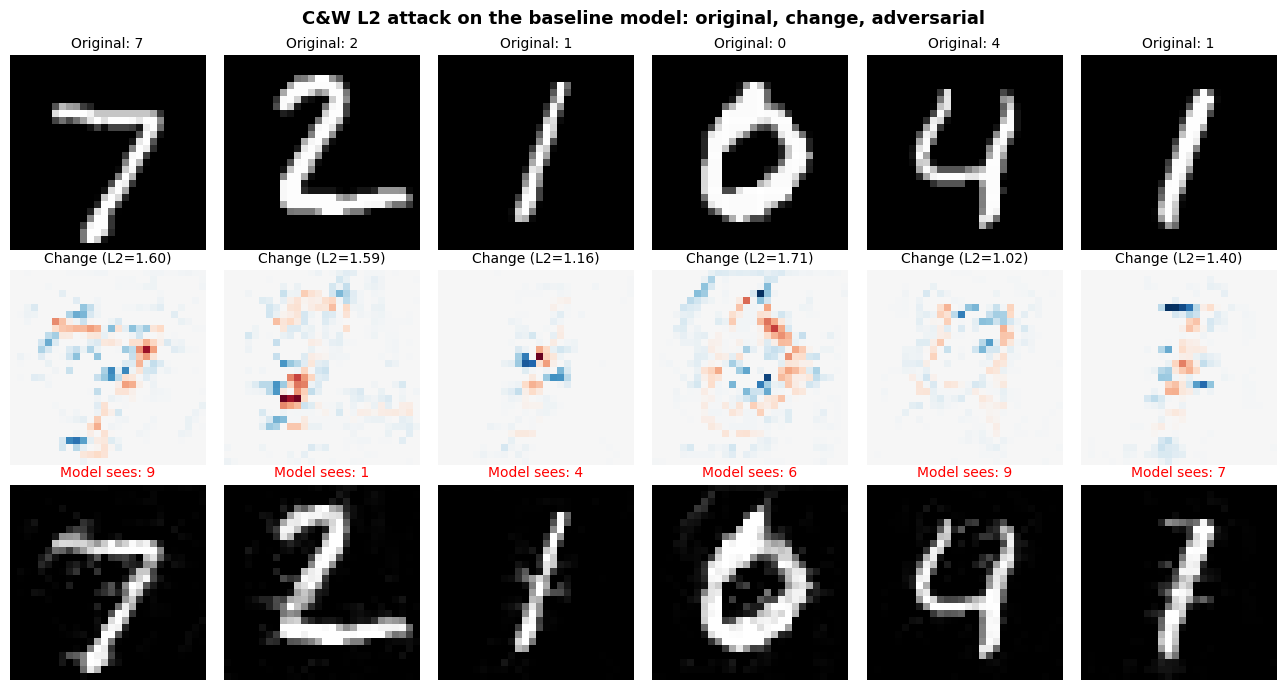

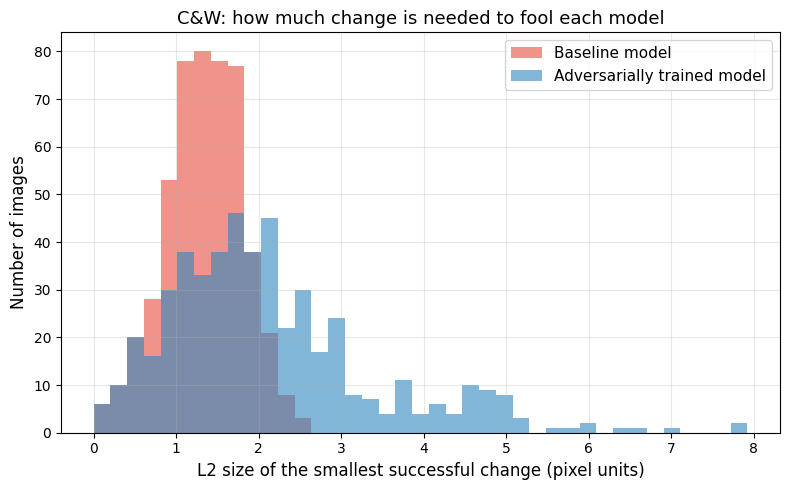


C&W results saved!


In [2]:
# CELL 2 - Carlini & Wagner (C&W) L2 attack
# Carlini & Wagner, "Towards Evaluating the Robustness of Neural Networks", 2017
#
# HOW IT WORKS:
# FGSM and PGD ask: "with a fixed noise budget, can I fool the model?"
# C&W asks the opposite: "what is the SMALLEST change that fools the model?"
# It solves an optimisation problem for every image:
#     minimise   (size of the change)  +  c * (how far the model is from being fooled)
# The constant c balances the two goals. A binary search finds, for each image,
# the smallest c that still fools the model, which gives the smallest change.
# The size of the change is measured with the L2 distance (in 0-1 pixel units).

def cw_l2_attack(model, x, y, binary_steps=5, steps=100, lr=0.1,
                 initial_c=1.0, kappa=0.0):
    """
    Untargeted C&W L2 attack.
    Returns the adversarial images, the L2 size of each change, and a
    True/False flag saying whether the attack succeeded for each image.
    """
    model.eval()
    n = len(x)
    x_pix = to_pixels(x)                              # work in 0-1 pixel space

    # Change of variable: pixel = (tanh(w) + 1) / 2 always stays between 0 and 1,
    # so the optimiser can never produce an invalid image.
    w_start = torch.atanh((2 * x_pix - 1) * 0.999999)

    c       = torch.full((n,), initial_c)
    c_low   = torch.zeros(n)
    c_high  = torch.full((n,), 1e10)

    best_l2  = torch.full((n,), float('inf'))
    best_adv = x.clone()
    onehot   = F.one_hot(y, 10).bool()

    for _ in range(binary_steps):
        w = w_start.clone().requires_grad_(True)
        optimizer = torch.optim.Adam([w], lr=lr)
        fooled_this_round = torch.zeros(n, dtype=torch.bool)

        for _ in range(steps):
            adv_pix = (torch.tanh(w) + 1) / 2
            logits  = model((adv_pix - MEAN) / STD)

            l2_sq = ((adv_pix - x_pix) ** 2).flatten(1).sum(1)
            true_logit  = logits[onehot]
            other_logit = logits.masked_fill(onehot, float('-inf')).max(1)[0]
            # This term is zero once another class beats the true class
            fool_term = torch.clamp(true_logit - other_logit + kappa, min=0)

            loss = (l2_sq + c * fool_term).sum()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Remember the smallest successful change found so far
            with torch.no_grad():
                fooled = logits.argmax(1) != y
                l2 = l2_sq.sqrt()
                better = fooled & (l2 < best_l2)
                best_l2[better]  = l2[better]
                best_adv[better] = ((adv_pix[better] - MEAN) / STD).detach()
                fooled_this_round |= fooled

        # Binary search on c: if we succeeded, try a smaller c; otherwise a larger one
        c_high = torch.where(fooled_this_round, torch.minimum(c_high, c), c_high)
        c_low  = torch.where(fooled_this_round, c_low, torch.maximum(c_low, c))
        c = torch.where(c_high < 1e9, (c_low + c_high) / 2, c * 10)

    success = torch.isfinite(best_l2)
    return best_adv, best_l2, success


def run_cw(model, name, n_images=500, batch_size=250):
    """Run C&W on the first n_images test images that the model classifies correctly."""
    correct = (predict(model, X_test).argmax(1) == y_test).nonzero().squeeze(1)[:n_images]
    x, y = X_test[correct], y_test[correct]
    advs, l2s, oks = [], [], []
    for i in tqdm(range(0, len(x), batch_size), desc=f"C&W vs {name}"):
        a, l, s = cw_l2_attack(model, x[i:i + batch_size], y[i:i + batch_size])
        advs.append(a); l2s.append(l); oks.append(s)
    adv, l2, ok = torch.cat(advs), torch.cat(l2s), torch.cat(oks)
    linf = (to_pixels(adv) - to_pixels(x)).abs().flatten(1).max(1)[0]
    return {
        "x": x, "y": y, "adv": adv, "l2": l2, "ok": ok,
        "success_rate": 100.0 * ok.float().mean().item(),
        "mean_l2":   l2[ok].mean().item(),
        "median_l2": l2[ok].median().item(),
        "mean_linf": linf[ok].mean().item(),
    }

print("Carlini & Wagner L2 attack")
print("=" * 50)
print("This cell takes roughly 5-10 minutes on CPU.\n")

adv_trained_model = load_model('../models/mnist_adversarial_trained.pth')

cw_base = run_cw(baseline_model,    "baseline model")
cw_adv  = run_cw(adv_trained_model, "adversarially trained model")

print(f"\n{'Model':<30} {'Success':>9} {'Mean L2':>9} {'Median L2':>10} {'Mean Linf':>10}")
print("-" * 72)
for name, r in [("Baseline", cw_base), ("Adversarially trained", cw_adv)]:
    print(f"{name:<30} {r['success_rate']:>8.1f}% {r['mean_l2']:>9.3f} "
          f"{r['median_l2']:>10.3f} {r['mean_linf']:>10.3f}")
print("\nL2 and Linf are measured in pixel units (0 = black, 1 = white).")
print("A larger L2 means the attacker had to change the image more to fool the model.")

# Figure 1: examples against the baseline model
fig, axes = plt.subplots(3, 6, figsize=(13, 7))
shown = cw_base["ok"].nonzero().squeeze(1)[:6]
adv_preds = predict(baseline_model, cw_base["adv"]).argmax(1)
for col, i in enumerate(shown):
    orig = to_pixels(cw_base["x"][i]).squeeze()
    adv  = to_pixels(cw_base["adv"][i]).squeeze()
    axes[0, col].imshow(orig, cmap='gray', vmin=0, vmax=1)
    axes[0, col].set_title(f"Original: {cw_base['y'][i].item()}", fontsize=10)
    axes[1, col].imshow(adv - orig, cmap='RdBu', vmin=-0.5, vmax=0.5)
    axes[1, col].set_title(f"Change (L2={cw_base['l2'][i]:.2f})", fontsize=10)
    axes[2, col].imshow(adv, cmap='gray', vmin=0, vmax=1)
    axes[2, col].set_title(f"Model sees: {adv_preds[i].item()}", fontsize=10, color='red')
    for row in range(3):
        axes[row, col].axis('off')
fig.suptitle("C&W L2 attack on the baseline model: original, change, adversarial",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/cw_examples.png', dpi=150)
plt.show()

# Figure 2: how much change was needed, baseline vs adversarially trained
plt.figure(figsize=(8, 5))
bins = np.linspace(0, max(cw_base["l2"][cw_base["ok"]].max().item(),
                          cw_adv["l2"][cw_adv["ok"]].max().item()), 40)
plt.hist(cw_base["l2"][cw_base["ok"]].numpy(), bins=bins, alpha=0.6,
         color='#e74c3c', label='Baseline model')
plt.hist(cw_adv["l2"][cw_adv["ok"]].numpy(), bins=bins, alpha=0.6,
         color='#2e86c1', label='Adversarially trained model')
plt.xlabel('L2 size of the smallest successful change (pixel units)', fontsize=12)
plt.ylabel('Number of images', fontsize=12)
plt.title('C&W: how much change is needed to fool each model', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/cw_l2_distribution.png', dpi=150)
plt.show()

with open('../results/cw_results.txt', 'w') as f:
    f.write("Carlini & Wagner L2 Attack Results on MNIST\n")
    f.write("=" * 45 + "\n")
    f.write("Settings: 5 binary search steps, 100 optimisation steps, lr 0.1, kappa 0\n")
    f.write("Distances are in pixel units (0-1 scale)\n\n")
    for name, r in [("Baseline", cw_base), ("Adversarially trained", cw_adv)]:
        f.write(f"{name}: images={len(r['x'])}  success={r['success_rate']:.1f}%  "
                f"mean L2={r['mean_l2']:.3f}  median L2={r['median_l2']:.3f}  "
                f"mean Linf={r['mean_linf']:.3f}\n")
print("\nC&W results saved!")

Backdoor Attack (BadNets)
Trigger: white 3x3 square, target class: 0
This cell trains 3 models and takes roughly 5-8 minutes on CPU.

Poison rate= 0.0%: Clean accuracy=99.09%  Backdoor success=0.10%


Poison 0.5% epoch 3/3: 100%|█████████████████████████████████████████████████████████| 938/938 [00:18<00:00, 49.62it/s]


Poison rate= 0.5%: Clean accuracy=98.88%  Backdoor success=98.04%  (300 poisoned images)


Poison 1.0% epoch 3/3: 100%|█████████████████████████████████████████████████████████| 938/938 [00:20<00:00, 46.29it/s]


Poison rate= 1.0%: Clean accuracy=98.83%  Backdoor success=99.76%  (600 poisoned images)


Poison 5.0% epoch 3/3: 100%|█████████████████████████████████████████████████████████| 938/938 [00:19<00:00, 47.39it/s]


Poison rate= 5.0%: Clean accuracy=98.89%  Backdoor success=99.99%  (3000 poisoned images)

Backdoored model saved to models/mnist_backdoored.pth


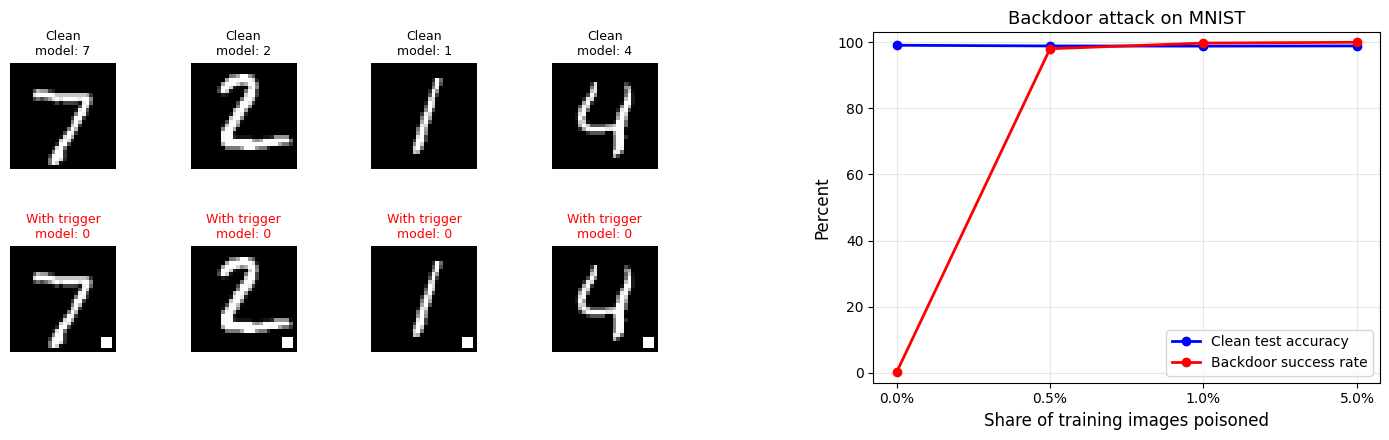

Backdoor results saved!


In [3]:
# CELL 3 - Backdoor attack (BadNets)
# Gu et al., "BadNets: Identifying Vulnerabilities in the Machine Learning
# Model Supply Chain", 2017
#
# HOW IT WORKS:
# The attacker adds a small "trigger" (here a white 3x3 square in the corner)
# to a few training images and relabels them as a chosen target class.
# The trained model behaves normally on clean images, so nobody notices,
# but any image carrying the trigger is classified as the target class.
# This is different from label flipping in notebook 2: clean accuracy stays
# high and the damage only appears when the attacker shows the trigger.

TARGET_CLASS = 0

def add_trigger(x):
    """Stamp a white 3x3 square near the bottom-right corner."""
    x = x.clone()
    x[:, :, 24:27, 24:27] = X_MAX
    return x

def backdoor_success_rate(model):
    """Share of triggered test images (true class not 0) classified as the target."""
    mask = y_test != TARGET_CLASS
    preds = predict(model, add_trigger(X_test[mask])).argmax(1)
    return 100.0 * (preds == TARGET_CLASS).float().mean().item()

print("Backdoor Attack (BadNets)")
print("=" * 50)
print(f"Trigger: white 3x3 square, target class: {TARGET_CLASS}")
print("This cell trains 3 models and takes roughly 5-8 minutes on CPU.\n")

# The clean baseline model is the 0% reference
backdoor_results = [(0.0, accuracy(baseline_model, X_test, y_test),
                     backdoor_success_rate(baseline_model))]
print(f"Poison rate= 0.0%: Clean accuracy={backdoor_results[0][1]:.2f}%  "
      f"Backdoor success={backdoor_results[0][2]:.2f}%")

poison_rates = [0.005, 0.01, 0.05]
rng = np.random.RandomState(0)
backdoored_model = None

for rate in poison_rates:
    n_poison = int(len(X_train) * rate)
    idx = torch.from_numpy(rng.choice(len(X_train), n_poison, replace=False))

    X_poisoned, y_poisoned = X_train.clone(), y_train.clone()
    X_poisoned[idx] = add_trigger(X_train[idx])
    y_poisoned[idx] = TARGET_CLASS

    model = train_model(X_poisoned, y_poisoned, epochs=3, seed=1,
                        desc=f"Poison {rate:.1%}")
    clean_acc = accuracy(model, X_test, y_test)
    success   = backdoor_success_rate(model)
    backdoor_results.append((rate, clean_acc, success))
    backdoored_model = model
    print(f"Poison rate={rate:>5.1%}: Clean accuracy={clean_acc:.2f}%  "
          f"Backdoor success={success:.2f}%  ({n_poison} poisoned images)")

# Keep the last (5%) backdoored model for the explainability notebook
torch.save(backdoored_model.state_dict(), '../models/mnist_backdoored.pth')
print("\nBackdoored model saved to models/mnist_backdoored.pth")

# Figure: what the trigger looks like, and how well the backdoor works
fig = plt.figure(figsize=(14, 4.5))
examples = (y_test != TARGET_CLASS).nonzero().squeeze(1)[:4]
triggered = add_trigger(X_test[examples])
trig_preds = predict(backdoored_model, triggered).argmax(1)
clean_preds = predict(backdoored_model, X_test[examples]).argmax(1)
for k, i in enumerate(examples):
    ax = fig.add_subplot(2, 8, k + 1)
    ax.imshow(to_pixels(X_test[i]).squeeze(), cmap='gray')
    ax.set_title(f"Clean\nmodel: {clean_preds[k].item()}", fontsize=9)
    ax.axis('off')
    ax = fig.add_subplot(2, 8, 8 + k + 1)
    ax.imshow(to_pixels(triggered[k]).squeeze(), cmap='gray')
    ax.set_title(f"With trigger\nmodel: {trig_preds[k].item()}", fontsize=9, color='red')
    ax.axis('off')

ax = fig.add_subplot(1, 2, 2)
labels = [f"{r[0]:.1%}" for r in backdoor_results]
ax.plot(labels, [r[1] for r in backdoor_results], 'b-o', linewidth=2,
        label='Clean test accuracy')
ax.plot(labels, [r[2] for r in backdoor_results], 'r-o', linewidth=2,
        label='Backdoor success rate')
ax.set_xlabel('Share of training images poisoned', fontsize=12)
ax.set_ylabel('Percent', fontsize=12)
ax.set_title('Backdoor attack on MNIST', fontsize=13)
ax.set_ylim(-3, 103)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/backdoor_attack.png', dpi=150)
plt.show()

with open('../results/backdoor_results.txt', 'w') as f:
    f.write("Backdoor (BadNets) Attack Results on MNIST\n")
    f.write("=" * 45 + "\n")
    f.write(f"Trigger: white 3x3 square (rows/cols 24-26), target class {TARGET_CLASS}\n\n")
    for rate, acc, success in backdoor_results:
        f.write(f"Poison rate={rate:.1%}: Clean accuracy={acc:.2f}%  "
                f"Backdoor success={success:.2f}%\n")
print("Backdoor results saved!")

Model Extraction Attack
Victim accuracy on the hold-out images: 99.30%
This cell trains 8 small models and takes roughly 3-5 minutes on CPU.

 Queries API output       Fidelity  Accuracy
---------------------------------------------
     100 probabilities      80.05%    80.05%
     100 label only         79.45%    79.65%
     500 probabilities      94.75%    94.80%
     500 label only         93.60%    93.70%
    2000 probabilities      97.90%    97.85%
    2000 label only         97.10%    97.25%
    8000 probabilities      98.95%    98.75%
    8000 label only         98.90%    98.85%


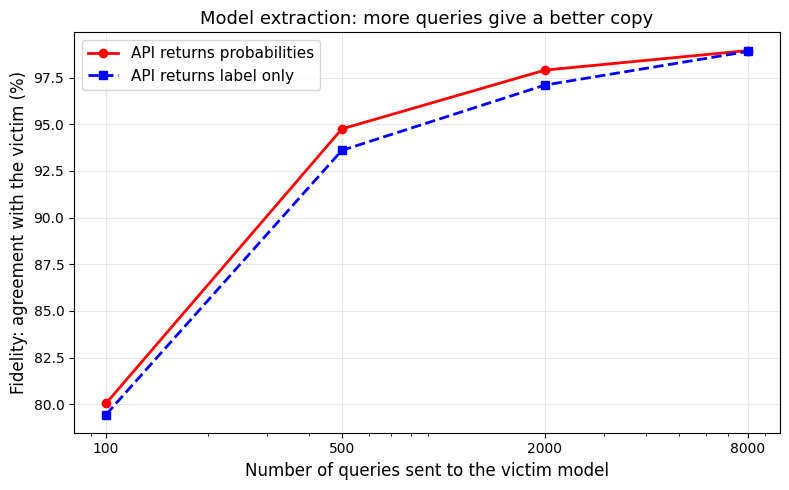


Extraction results saved!


In [4]:
# CELL 4 - Model extraction (model stealing)
# Tramer et al., "Stealing Machine Learning Models via Prediction APIs", 2016
#
# HOW IT WORKS:
# The attacker cannot see the model's weights or its training data.
# They can only send images to the prediction API and read the answers.
# They use those answers as labels to train their own copy ("substitute").
# We measure:
#   Fidelity = how often the copy gives the same answer as the original
#   Accuracy = how often the copy gives the correct answer
# We also compare an API that returns full probabilities with one that
# returns only the predicted label.
#
# Assumptions: the attacker has unlabelled digit images to send (we use
# 8,000 test images) and uses the same network design as the victim.

victim = baseline_model

X_query,   y_query_true = X_test[:8000], y_test[:8000]   # attacker's unlabelled images
X_holdout, y_holdout    = X_test[8000:], y_test[8000:]   # used only to measure the copy

def query_api(model, X, probabilities=True):
    """What the prediction API returns for each image."""
    probs = torch.softmax(predict(model, X), dim=1)
    if probabilities:
        return probs
    return F.one_hot(probs.argmax(1), 10).float()         # label only

def train_substitute(X, soft_labels, steps=600, batch_size=64, seed=0):
    """Train a copy using only the API's answers as labels."""
    torch.manual_seed(seed)
    model = SimpleCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    model.train()
    for _ in range(steps):
        idx = torch.randint(0, len(X), (batch_size,))
        optimizer.zero_grad()
        log_probs = F.log_softmax(model(X[idx]), dim=1)
        loss = -(soft_labels[idx] * log_probs).sum(1).mean()
        loss.backward()
        optimizer.step()
    model.eval()
    return model

def fidelity(copy, original, X):
    """Percent of images where the copy and the original give the same answer."""
    return 100.0 * (predict(copy, X).argmax(1) ==
                    predict(original, X).argmax(1)).float().mean().item()

print("Model Extraction Attack")
print("=" * 50)
print(f"Victim accuracy on the hold-out images: {accuracy(victim, X_holdout, y_holdout):.2f}%")
print("This cell trains 8 small models and takes roughly 3-5 minutes on CPU.\n")

query_budgets = [100, 500, 2000, 8000]
extraction_results = []

print(f"{'Queries':>8} {'API output':<15} {'Fidelity':>9} {'Accuracy':>9}")
print("-" * 45)
for n_queries in query_budgets:
    for probabilities in [True, False]:
        answers = query_api(victim, X_query[:n_queries], probabilities)
        copy = train_substitute(X_query[:n_queries], answers)
        fid = fidelity(copy, victim, X_holdout)
        acc = accuracy(copy, X_holdout, y_holdout)
        kind = "probabilities" if probabilities else "label only"
        extraction_results.append((n_queries, kind, fid, acc))
        print(f"{n_queries:>8} {kind:<15} {fid:>8.2f}% {acc:>8.2f}%")

# Figure
plt.figure(figsize=(8, 5))
for kind, style in [("probabilities", 'r-o'), ("label only", 'b--s')]:
    rows = [r for r in extraction_results if r[1] == kind]
    plt.plot([r[0] for r in rows], [r[2] for r in rows], style, linewidth=2,
             label=f"API returns {kind}")
plt.xscale('log')
plt.xticks(query_budgets, [str(q) for q in query_budgets])
plt.xlabel('Number of queries sent to the victim model', fontsize=12)
plt.ylabel('Fidelity: agreement with the victim (%)', fontsize=12)
plt.title('Model extraction: more queries give a better copy', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/model_extraction.png', dpi=150)
plt.show()

with open('../results/extraction_results.txt', 'w') as f:
    f.write("Model Extraction Attack Results on MNIST\n")
    f.write("=" * 45 + "\n")
    f.write("Victim: baseline SimpleCNN. Substitute: SimpleCNN, 600 training steps.\n")
    f.write("Fidelity and accuracy measured on 2,000 hold-out test images.\n\n")
    for n_queries, kind, fid, acc in extraction_results:
        f.write(f"Queries={n_queries:>5}  API output={kind:<14} "
                f"Fidelity={fid:.2f}%  Accuracy={acc:.2f}%\n")
print("\nExtraction results saved!")

In [5]:
# CELL 5 - Summary of this notebook

print("=" * 60)
print("ADDITIONAL ATTACKS - SUMMARY")
print("=" * 60)
print("\n1. Carlini & Wagner (smallest change that fools the model)")
print(f"   Baseline model       : success {cw_base['success_rate']:.1f}%, "
      f"mean L2 {cw_base['mean_l2']:.3f}")
print(f"   Adversarially trained: success {cw_adv['success_rate']:.1f}%, "
      f"mean L2 {cw_adv['mean_l2']:.3f}")
print("\n2. Backdoor (hidden trigger planted through poisoned training data)")
for rate, acc, success in backdoor_results:
    print(f"   Poison {rate:>5.1%}: clean accuracy {acc:.2f}%, backdoor success {success:.2f}%")
print("\n3. Model extraction (copying the model through its prediction API)")
for n_queries, kind, fid, acc in extraction_results:
    print(f"   {n_queries:>5} queries, {kind:<13}: fidelity {fid:.2f}%, accuracy {acc:.2f}%")
print("\nFigures saved to figures/, results saved to results/")

ADDITIONAL ATTACKS - SUMMARY

1. Carlini & Wagner (smallest change that fools the model)
   Baseline model       : success 100.0%, mean L2 1.340
   Adversarially trained: success 99.2%, mean L2 2.128

2. Backdoor (hidden trigger planted through poisoned training data)
   Poison  0.0%: clean accuracy 99.09%, backdoor success 0.10%
   Poison  0.5%: clean accuracy 98.88%, backdoor success 98.04%
   Poison  1.0%: clean accuracy 98.83%, backdoor success 99.76%
   Poison  5.0%: clean accuracy 98.89%, backdoor success 99.99%

3. Model extraction (copying the model through its prediction API)
     100 queries, probabilities: fidelity 80.05%, accuracy 80.05%
     100 queries, label only   : fidelity 79.45%, accuracy 79.65%
     500 queries, probabilities: fidelity 94.75%, accuracy 94.80%
     500 queries, label only   : fidelity 93.60%, accuracy 93.70%
    2000 queries, probabilities: fidelity 97.90%, accuracy 97.85%
    2000 queries, label only   : fidelity 97.10%, accuracy 97.25%
    8000 que